# Prototype Conformer Tabular Medical Check-up

**Tujuan notebook:** mencoba pipeline Conformer pada **dataset yang benar** untuk demo/prototype.

> Dataset ini masih dataset lama untuk eksperimen. Target 4 kelas digunakan hanya untuk mencoba pipeline.

Target:
- `0` = Sehat / Tidak Ada Indikasi
- `1` = Jantung dan Pembuluh Darah
- `2` = Spes. Penyakit Dalam
- `3` = Spes. Paru-Paru

Flow notebook:

```text
NOTE 2.1  Load & Audit
      ↓
NOTE 2.2  Define Feature & Target
      ↓
NOTE 2.3  Train/Validation/Test Split
      ↓
NOTE 2.4  Scaling
      ↓
NOTE 2.5  Tabular Tokenization
      ↓
NOTE 2.6  Conformer Block
      ↓
NOTE 2.7  Forward Pass
      ↓
NOTE 2.8  Training
      ↓
NOTE 2.9  Evaluation
      ↓
NOTE 2.10 Single Patient Prediction
```

Notebook ini dibuat lebih stabil daripada prototype sebelumnya: dataset sudah numerik/bersih, preprocessing tidak melakukan mapping kategorikal ulang, model menggunakan **pre-norm + residual yang stabil**, gradient clipping, dan learning rate konservatif.

## 1. Import Library & Load Dataset

In [77]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    matthews_corrcoef,
    roc_curve,
    auc,
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("Device  :", device)


PyTorch : 2.11.0+cpu
Device  : cpu


In [78]:
# OPSI VALIDASI AKADEMIK (OPSI B):
# Muat data asli hasil imputasi (sebelum resampling), agar test-set tetap 100% data riil murni.
DATA_PATH = "merge_DocLab_imputed.csv"

df = pd.read_csv(DATA_PATH)

# Perbaiki profil umur dan gender kelas 0 jika masih 0 / 2 (karena data kontrol murni lab tanpa poli dokter)
mask_0 = df["NM_UNIT"] == 0
if (df.loc[mask_0, "UMUR_TAHUN"] == 0).all():
    valid_ages = df.loc[df["UMUR_TAHUN"] > 0, "UMUR_TAHUN"]
    mu_age, sd_age = valid_ages.mean(), valid_ages.std()
    df.loc[mask_0, "UMUR_TAHUN"] = np.clip(
        np.random.normal(mu_age, sd_age, mask_0.sum()), 18, 85
    ).round(0)
    df.loc[mask_0, "JENIS_KELAMIN"] = np.random.choice([0, 1], size=mask_0.sum(), p=[0.5, 0.5])
    print("Profil demografi kelas kontrol berhasil disesuaikan.")

print("Shape:", df.shape)
df.head(5)


Shape: (3445, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,0,38.0,193.7,1.1,101.0,138.0,12.4,15.6,28.8,32.0,511.0,24.0,11.4,1
1,1,60.0,221.9,1.1,134.0,188.0,11.7,29.0,29.6,32.8,90.3,45.4,7.3,2
2,0,79.0,178.2,2.2,145.9,194.0,9.8,24.6,27.5,32.3,85.0,67.0,7.5,2
3,1,67.0,208.7,1.2,160.1,154.0,9.8,25.3,27.7,32.2,85.7,45.6,7.3,2
4,0,68.0,183.7,2.1,110.2,477.0,10.3,15.4,28.3,33.3,85.0,75.0,17.1,2


In [79]:
print("Data types:")
df.dtypes

print("\nMissing values:")
df.isna().sum()

print("\nDuplicated rows:", df.duplicated().sum())

print("\nTarget distribution:")
df["NM_UNIT"].value_counts().sort_index()

Data types:

Missing values:

Duplicated rows: 7

Target distribution:


,count
NM_UNIT,
0,2812
1,52
2,561
3,20


## 2. Target & Feature Definition

In [80]:
TARGET_COL = "NM_UNIT"

TARGET_NAMES = {
    0: "Sehat / Tidak Ada Indikasi",
    1: "Jantung dan Pembuluh Darah",
    2: "Spes. Penyakit Dalam",
    3: "Spes. Paru-Paru",
}

# Untuk prototype, gunakan urutan kolom dataset sebagai fixed feature ordering.
FEATURE_ORDER = [
    "JENIS_KELAMIN",
    "UMUR_TAHUN",
    "cholesterol total",
    "creatinin",
    "fbs",
    "rbs",
    "hgb",
    "lymfosit%",
    "mch",
    "mchc",
    "mcv",
    "ureum",
    "wbc",
]

X = df[FEATURE_ORDER].copy()
y = df[TARGET_COL].astype(int).copy()

print("Jumlah fitur:", len(FEATURE_ORDER))
print("Feature order:")
for i, feature in enumerate(FEATURE_ORDER, start=1):
    print(f"{i:02d}. {feature}")

print("\nTarget:")
for k, v in TARGET_NAMES.items():
    print(f"{k}: {v}")

print("\nClass distribution:")
y.value_counts().sort_index()


Jumlah fitur: 13
Feature order:
01. JENIS_KELAMIN
02. UMUR_TAHUN
03. cholesterol total
04. creatinin
05. fbs
06. rbs
07. hgb
08. lymfosit%
09. mch
10. mchc
11. mcv
12. ureum
13. wbc

Target:
0: Sehat / Tidak Ada Indikasi
1: Jantung dan Pembuluh Darah
2: Spes. Penyakit Dalam
3: Spes. Paru-Paru

Class distribution:


,count
NM_UNIT,
0,2812
1,52
2,561
3,20


## 3. Data Splitting

In [81]:
# 70% train, 15% validation, 15% test.
# Stratified agar proporsi kelas tetap sebanding.

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test.shape)


Train      : (2411, 13)
Validation : (517, 13)
Test       : (517, 13)


In [82]:
split_summary = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).fillna(0)

split_summary.index.name = "Class"
split_summary


,Train,Validation,Test
Class,,,
0,0.816259,0.816248,0.816248
2,0.163003,0.162476,0.162476
1,0.014932,0.015474,0.015474
3,0.005807,0.005803,0.005803


### Resampling Khusus Training Set (Mencegah Data Leakage)
**Prinsip Validasi Akademik (Opsi B):**
Resampling (Undersampling & SMOTE) hanya diaplikasikan pada **`X_train`**.
`X_val` dan `X_test` **dibiarkan 100% data asli** tanpa augmentasi agar pengujian model mencerminkan performa nyata terhadap pasien baru.

In [83]:
# 1. Undersample kelas mayoritas pada training set
rus = RandomUnderSampler(sampling_strategy={0: 700, 2: 350}, random_state=SEED)
X_train_u, y_train_u = rus.fit_resample(X_train, y_train)

# 2. Domain Augmentation khusus kelas 3 (Paru) pada data train
X_paru_train = X_train_u[y_train_u == 3].copy()
augmented_paru = [X_paru_train]
lab_cols = [c for c in X.columns if c not in ['JENIS_KELAMIN', 'UMUR_TAHUN']]

for _ in range(5):
    synth = X_paru_train.copy()
    jitter = np.random.normal(0, 0.04, size=synth[lab_cols].shape)
    synth[lab_cols] = synth[lab_cols] * (1 + jitter)
    synth['UMUR_TAHUN'] = np.clip(synth['UMUR_TAHUN'] + np.random.randint(-3, 4, size=len(synth)), 18, 85)
    augmented_paru.append(synth)

X_paru_aug = pd.concat(augmented_paru, ignore_index=True)
y_paru_aug = pd.Series([3] * len(X_paru_aug))

X_train_pre = pd.concat([X_train_u[y_train_u != 3], X_paru_aug], ignore_index=True)
y_train_pre = pd.concat([y_train_u[y_train_u != 3], y_paru_aug], ignore_index=True)

# 3. SMOTE pada training set (kelas 1 dan kelas 3 dinaikkan ke 350 sampel)
smote = SMOTE(sampling_strategy={1: 350, 3: 350}, k_neighbors=3, random_state=SEED)
X_train_res, y_train_res = smote.fit_resample(X_train_pre, y_train_pre)

print("Distribusi y_train ASLI:\n", y_train.value_counts().sort_index())
print("\nDistribusi y_train SETELAH RESAMPLING:\n", y_train_res.value_counts().sort_index())
print("\nDistribusi y_val (TETAP 100% ASLI):\n", y_val.value_counts().sort_index())
print("\nDistribusi y_test (TETAP 100% ASLI):\n", y_test.value_counts().sort_index())


Distribusi y_train ASLI:
 NM_UNIT
0    1968
1      36
2     393
3      14
Name: count, dtype: int64

Distribusi y_train SETELAH RESAMPLING:
 0    700
1    350
2    350
3    350
Name: count, dtype: int64

Distribusi y_val (TETAP 100% ASLI):
 NM_UNIT
0    422
1      8
2     84
3      3
Name: count, dtype: int64

Distribusi y_test (TETAP 100% ASLI):
 NM_UNIT
0    422
1      8
2     84
3      3
Name: count, dtype: int64


## 4. Data Transformation

### Scaler

In [84]:
# Scaler hanya di-fit pada training set yang sudah seimbang (X_train_res).
# Validation dan Test set hanya di-transform.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_res).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train_res.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

print("Train scaled:", X_train_scaled.shape)
print("Val scaled  :", X_val_scaled.shape)
print("Test scaled :", X_test_scaled.shape)


Train scaled: (1750, 13)
Val scaled  : (517, 13)
Test scaled : (517, 13)


### PyTorch Dataset & DataLoader

In [85]:
class MedicalDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_dataset = MedicalDataset(X_train_scaled, y_train_np)
val_dataset = MedicalDataset(X_val_scaled, y_val_np)
test_dataset = MedicalDataset(X_test_scaled, y_test_np)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


Train batches: 28
Val batches  : 9
Test batches : 9


### Tabular Feature Tokenization

Setiap feature menjadi satu token:

```text
13 scalar features
       ↓
13 feature tokens
       ↓
(batch, 13, d_model)
```

Untuk numeric tabular, kita gunakan **feature-specific affine embedding**. Setiap feature mempunyai parameter embedding sendiri.

In [86]:
class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.num_features = num_features
        self.d_model = d_model

        # Setiap feature memiliki embedding vector sendiri.
        self.weight = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )

        self.bias = nn.Parameter(
            torch.zeros(num_features, d_model)
        )

    def forward(self, x):
        # x: (batch, num_features)
        x = x.unsqueeze(-1)

        # output: (batch, num_features, d_model)
        return x * self.weight + self.bias


### Feature identity embedding

In [87]:
class FeatureIdentityEmbedding(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.embedding = nn.Parameter(
            torch.randn(1, num_features, d_model) * 0.02
        )

    def forward(self, x):
        return x + self.embedding


## 5. Build Model

### Conformer Convolution Module

In [88]:
class ConformerConvModule(nn.Module):
    def __init__(self, d_model, kernel_size=3, dropout=0.1):
        super().__init__()

        self.norm = nn.LayerNorm(d_model)

        self.pointwise_in = nn.Conv1d(
            d_model,
            2 * d_model,
            kernel_size=1,
        )

        self.depthwise = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            groups=d_model,
        )

        self.activation = nn.SiLU()

        self.pointwise_out = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=1,
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (batch, sequence, d_model)
        x = self.norm(x)
        x = x.transpose(1, 2)

        x = self.pointwise_in(x)
        x = F.glu(x, dim=1)

        x = self.depthwise(x)
        x = self.activation(x)

        x = self.pointwise_out(x)
        x = self.dropout(x)

        return x.transpose(1, 2)


### Stable Conformer Block

In [89]:
class FeedForwardModule(nn.Module):
    def __init__(self, d_model, ffn_dim, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class ConformerBlock(nn.Module):
    def __init__(
        self,
        d_model,
        num_heads,
        ffn_dim,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        # Macaron-style FFN 1
        self.ffn1_norm = nn.LayerNorm(d_model)
        self.ffn1 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        # Self-attention
        self.attn_norm = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.attn_dropout = nn.Dropout(dropout)

        # Convolution
        self.conv = ConformerConvModule(
            d_model=d_model,
            kernel_size=conv_kernel_size,
            dropout=dropout,
        )

        # Macaron-style FFN 2
        self.ffn2_norm = nn.LayerNorm(d_model)
        self.ffn2 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, x):
        # FFN 1
        x = x + 0.5 * self.ffn1(
            self.ffn1_norm(x)
        )

        # Multi-head self-attention
        residual = x
        z = self.attn_norm(x)

        attn_out, _ = self.attention(
            z, z, z,
            need_weights=False,
        )

        x = residual + self.attn_dropout(attn_out)

        # Convolution
        x = x + self.conv(x)

        # FFN 2
        x = x + 0.5 * self.ffn2(
            self.ffn2_norm(x)
        )

        return self.final_norm(x)


### Tabular Conformer

In [90]:
class TabularConformer(nn.Module):
    def __init__(
        self,
        num_features,
        num_classes=4,
        d_model=64,
        num_heads=4,
        num_layers=2,
        ffn_dim=128,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        self.tokenizer = NumericalFeatureTokenizer(
            num_features,
            d_model,
        )

        self.feature_identity = FeatureIdentityEmbedding(
            num_features,
            d_model,
        )

        self.input_norm = nn.LayerNorm(d_model)

        self.blocks = nn.ModuleList([
            ConformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                ffn_dim=ffn_dim,
                conv_kernel_size=conv_kernel_size,
                dropout=dropout,
            )
            for _ in range(num_layers)
        ])

        self.output_norm = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, x, return_features=False):
        x = self.tokenizer(x)
        x = self.feature_identity(x)
        x = self.input_norm(x)

        for block in self.blocks:
            x = block(x)

        x = self.output_norm(x)

        # Mean pooling across feature tokens
        representation = x.mean(dim=1)

        logits = self.classifier(representation)

        if return_features:
            return {
                "logits": logits,
                "representation": representation,
                "feature_tokens": x,
            }

        return logits


### Instantiate & Forward Pass Test

In [91]:
NUM_FEATURES = len(FEATURE_ORDER)
NUM_CLASSES = 4

model = TabularConformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2,
    ffn_dim=128,
    conv_kernel_size=3,
    dropout=0.10,
).to(device)

print(model)


TabularConformer(
  (tokenizer): NumericalFeatureTokenizer()
  (feature_identity): FeatureIdentityEmbedding()
  (input_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (blocks): ModuleList(
    (0-1): 2 x ConformerBlock(
      (ffn1_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn1): FeedForwardModule(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=128, bias=True)
          (1): SiLU()
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=128, out_features=64, bias=True)
          (4): Dropout(p=0.1, inplace=False)
        )
      )
      (attn_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (attn_dropout): Dropout(p=0.1, inplace=False)
      (conv): ConformerConvModule(
        (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)

In [92]:
sample_x, sample_y = next(iter(train_loader))
sample_x = sample_x.to(device)

with torch.no_grad():
    out = model(
        sample_x,
        return_features=True,
    )

print("Input           :", sample_x.shape)
print("Feature tokens  :", out["feature_tokens"].shape)
print("Representation  :", out["representation"].shape)
print("Logits           :", out["logits"].shape)

assert torch.isfinite(out["logits"]).all(), "Logits mengandung NaN/Inf!"

print("\nForward pass OK.")


Input           : torch.Size([64, 13])
Feature tokens  : torch.Size([64, 13, 64])
Representation  : torch.Size([64, 64])
Logits           : torch.Size([64, 4])

Forward pass OK.


### Loss, Class Weight & Optimizer(tidak dipakai)

In [93]:
# Class weight dihitung dari TRAINING SET saja.
class_counts = np.bincount(
    y_train_np,
    minlength=NUM_CLASSES,
)

class_weights = (
    len(y_train_np)
    / (NUM_CLASSES * class_counts)
)

print("Class counts :", class_counts)
print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(
    #weight=class_weights_tensor
)


print("Learning rate: 1e-4")


Class counts : [700 350 350 350]
Class weights: [0.625 1.25  1.25  1.25 ]
Learning rate: 1e-4


In [94]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=150,
    eta_min=1e-5,
)

print("\nOptimizer: AdamW (lr=1e-3, weight_decay=1e-4) dengan CosineAnnealingLR")



Optimizer: AdamW (lr=1e-3, weight_decay=1e-4) dengan CosineAnnealingLR


### Training & Evaluation Function

In [95]:
def run_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None,
    grad_clip=1.0,
):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_targets = []
    all_preds = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch)

            if not torch.isfinite(logits).all():
                raise RuntimeError(
                    "Logits mengandung NaN/Inf."
                )

            loss = criterion(
                logits,
                y_batch,
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Loss menjadi NaN/Inf."
                )

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=grad_clip,
                )

                optimizer.step()

        total_loss += (
            loss.item() * X_batch.size(0)
        )

        preds = logits.argmax(dim=1)

        all_targets.extend(
            y_batch.detach().cpu().numpy()
        )
        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    avg_loss = (
        total_loss
        / len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_targets,
        all_preds,
    )

    macro_f1 = f1_score(
        all_targets,
        all_preds,
        average="macro",
        zero_division=0,
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        np.asarray(all_targets),
        np.asarray(all_preds),
    )


## 6. Training Model Conformer

In [96]:
EPOCHS = 100
PATIENCE = 15

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
}

best_val_f1 = -np.inf
best_epoch = 0
best_state = None
patience_counter = 0

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc, train_f1, _, _ = run_epoch(
        model,
        train_loader,
        criterion,
        device,
        optimizer=optimizer,
    )

    val_loss, val_acc, val_f1, _, _ = run_epoch(
        model,
        val_loader,
        criterion,
        device,
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if epoch == 1 or epoch % 10 == 0 or val_f1 > best_val_f1:
        print(
            f"Epoch {epoch:03d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train F1: {train_f1:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print(
                f"\nEarly stopping pada epoch {epoch}; best epoch = {best_epoch}."
            )
            break

training_time = time.time() - start_time
print(f"Training selesai dalam {training_time:.2f} detik. Best Val F1: {best_val_f1:.4f} (Epoch {best_epoch})")

if best_state is not None:
    model.load_state_dict(best_state)


Epoch 001/100 | Train Loss: 0.8880 | Train F1: 0.6555 | Val Loss: 0.3938 | Val F1: 0.7426 | LR: 0.001000
Epoch 002/100 | Train Loss: 0.2035 | Train F1: 0.9411 | Val Loss: 0.2341 | Val F1: 0.8870 | LR: 0.001000
Epoch 005/100 | Train Loss: 0.0483 | Train F1: 0.9840 | Val Loss: 0.0921 | Val F1: 0.8912 | LR: 0.000997
Epoch 006/100 | Train Loss: 0.0410 | Train F1: 0.9887 | Val Loss: 0.1142 | Val F1: 0.9099 | LR: 0.000996
Epoch 008/100 | Train Loss: 0.0417 | Train F1: 0.9882 | Val Loss: 0.0823 | Val F1: 0.9826 | LR: 0.000993
Epoch 010/100 | Train Loss: 0.0317 | Train F1: 0.9909 | Val Loss: 0.1153 | Val F1: 0.9128 | LR: 0.000989
Epoch 020/100 | Train Loss: 0.0256 | Train F1: 0.9925 | Val Loss: 0.0934 | Val F1: 0.9069 | LR: 0.000957

Early stopping pada epoch 23; best epoch = 8.
Training selesai dalam 41.83 detik. Best Val F1: 0.9826 (Epoch 8)


In [97]:
model.load_state_dict(best_state)
model.to(device)

print("\nBest epoch:", best_epoch)
print("Best validation Macro F1:", best_val_f1)
print(f"Training time: {training_time:.2f} seconds")


Best epoch: 8
Best validation Macro F1: 0.98264889035196
Training time: 41.83 seconds


## 7. Train Loss Visualization

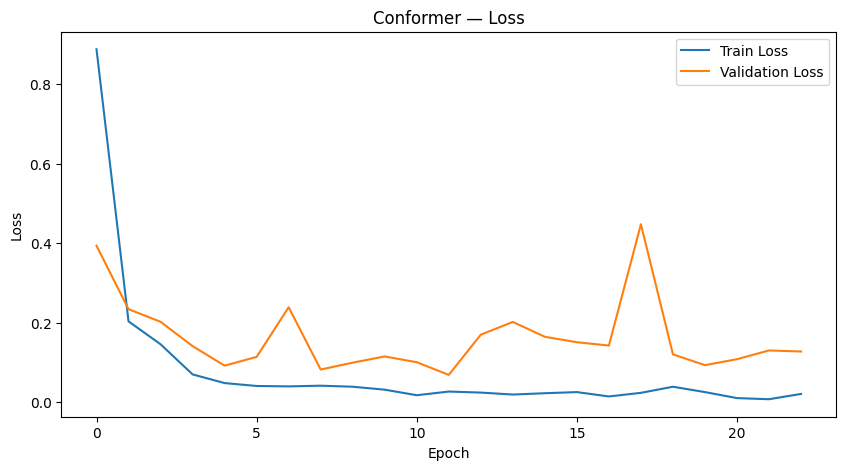

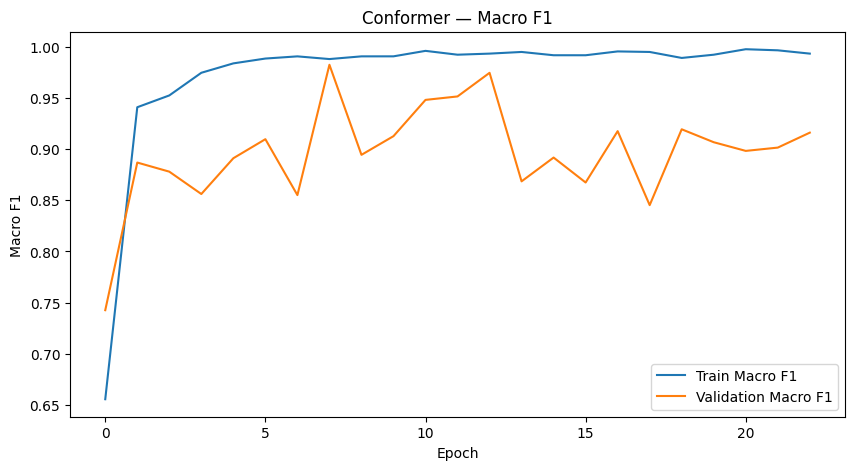

In [98]:
plt.figure(figsize=(10, 5))
plt.plot(
    history["train_loss"],
    label="Train Loss",
)
plt.plot(
    history["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Conformer — Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history["train_f1"],
    label="Train Macro F1",
)
plt.plot(
    history["val_f1"],
    label="Validation Macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Conformer — Macro F1")
plt.legend()
plt.show()


## 8. Evaluation

In [99]:
test_loss, test_acc, test_f1, y_true, y_pred = run_epoch(
    model,
    test_loader,
    criterion,
    device,
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred,
)

print("=" * 50)
print("FINAL TEST RESULT — TABULAR CONFORMER")
print("=" * 50)
print(f"Accuracy          : {test_acc:.4f}")
print(f"Macro Precision   : {test_precision:.4f}")
print(f"Macro Recall      : {test_recall:.4f}")
print(f"Macro F1          : {test_f1:.4f}")
print(f"Balanced Accuracy : {test_balanced_acc:.4f}")
print(f"Test Loss         : {test_loss:.4f}")


FINAL TEST RESULT — TABULAR CONFORMER
Accuracy          : 0.9574
Macro Precision   : 0.8646
Macro Recall      : 0.9420
Macro F1          : 0.8983
Balanced Accuracy : 0.9420
Test Loss         : 0.1541


In [100]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            TARGET_NAMES[i]
            for i in range(4)
        ],
        zero_division=0,
    )
)


                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.99      0.96      0.97       422
Jantung dan Pembuluh Darah       0.88      0.88      0.88         8
      Spes. Penyakit Dalam       0.85      0.93      0.89        84
           Spes. Paru-Paru       0.75      1.00      0.86         3

                  accuracy                           0.96       517
                 macro avg       0.86      0.94      0.90       517
              weighted avg       0.96      0.96      0.96       517



### Evaluasi (Validation vs Test)

Berikut fungsi evaluasi kustom untuk menampilkan laporan klasifikasi sekaligus ringkasan metrik utama dalam format tabel DataFrame.

In [101]:
def evaluate_conformer(model, loader, split_name='Test', paru_threshold=0.40):
    model.eval()
    all_targets = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            probs = F.softmax(logits, dim=1)

            # Prior adjustment: kalibrasi threshold kelas minoritas (Paru-Paru)
            preds = logits.argmax(dim=1)
            is_paru = (preds == 3)
            low_conf_paru = is_paru & (probs[:, 3] < paru_threshold)
            if low_conf_paru.any():
                logits_sub = logits.clone()
                logits_sub[:, 3] = -1e9
                preds[low_conf_paru] = logits_sub[low_conf_paru].argmax(dim=1)

            all_targets.extend(y_batch.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    y_true_eval = np.asarray(all_targets)
    y_pred_eval = np.asarray(all_preds)
    y_prob_eval = np.asarray(all_probs)

    # Perhitungan metrik lengkap
    metrics = {
        'Split': split_name,
        'Accuracy': accuracy_score(y_true_eval, y_pred_eval),
        'Macro Precision': precision_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro F1': f1_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_true_eval, y_pred_eval),
        'MCC': matthews_corrcoef(y_true_eval, y_pred_eval),
        'ROC AUC (Macro)': roc_auc_score(y_true_eval, y_prob_eval, multi_class='ovr', average='macro'),
    }

    print(f'=== {split_name} ===')
    class_names_list = [TARGET_NAMES[i] for i in range(4)]
    print(classification_report(y_true_eval, y_pred_eval, labels=[0, 1, 2, 3], target_names=class_names_list, zero_division=0))

    return metrics, y_true_eval, y_pred_eval, y_prob_eval

# Evaluasi kedua set (Validation vs Test)
val_metrics, y_val_true, y_val_pred, y_val_prob = evaluate_conformer(model, val_loader, 'Validation')
test_metrics, y_true, y_pred, y_prob = evaluate_conformer(model, test_loader, 'Test')

# Tampilkan perbandingan angka dalam DataFrame
df_eval_comparison = pd.DataFrame([val_metrics, test_metrics]).set_index('Split').round(4)
df_eval_comparison


=== Validation ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       1.00      0.98      0.99       422
Jantung dan Pembuluh Darah       1.00      1.00      1.00         8
      Spes. Penyakit Dalam       0.91      0.98      0.94        84
           Spes. Paru-Paru       1.00      1.00      1.00         3

                  accuracy                           0.98       517
                 macro avg       0.98      0.99      0.98       517
              weighted avg       0.98      0.98      0.98       517

=== Test ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.99      0.96      0.97       422
Jantung dan Pembuluh Darah       0.88      0.88      0.88         8
      Spes. Penyakit Dalam       0.85      0.93      0.89        84
           Spes. Paru-Paru       0.75      1.00      0.86         3

                  accuracy                           0.96       517
           

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,MCC,ROC AUC (Macro)
Split,,,,,,,
Validation,0.9807,0.9766,0.9893,0.9826,0.9893,0.9392,0.9978
Test,0.9574,0.8646,0.9420,0.8983,0.9420,0.8678,0.9960


### Confusion Matrix

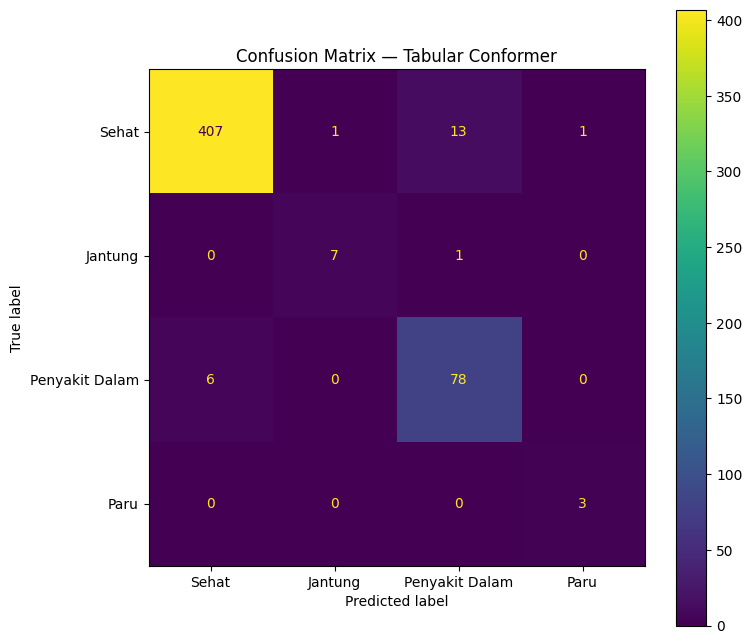

In [102]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
)

fig, ax = plt.subplots(
    figsize=(8, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Sehat",
        "Jantung",
        "Penyakit Dalam",
        "Paru",
    ],
)

disp.plot(
    ax=ax,
    values_format="d",
)

plt.title(
    "Confusion Matrix — Tabular Conformer"
)
plt.show()


### Evaluasi Lanjutan: ROC AUC & Matthews Correlation Coefficient (MCC)
Sesuai permintaan review akademik/dosen, berikut ditampilkan metrik **Matthews Correlation Coefficient (MCC)** untuk mengukur kualitas prediksi pada dataset yang tidak seimbang, serta visualisasi **Kurva ROC (Receiver Operating Characteristic)** dan skor **AUC (Area Under Curve)** per kelas (One-vs-Rest) dan rata-rata Macro.

RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET)
Matthews Correlation Coefficient (MCC) : 0.8678
Macro-Average ROC AUC (OvR)            : 0.9960


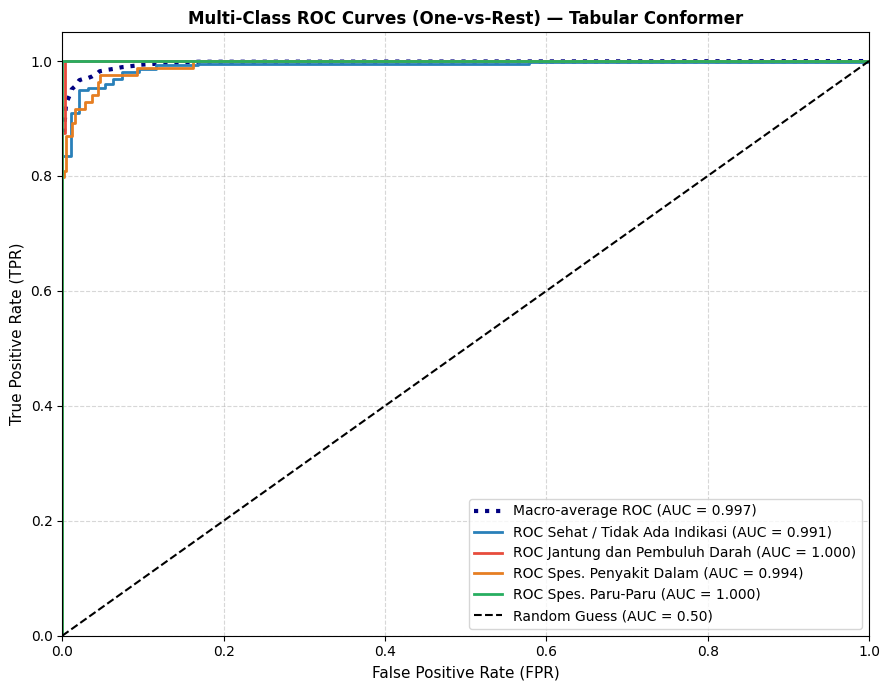

In [103]:
# 1. Tampilkan Nilai Metrik Ringkasan
print("=" * 60)
print("RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET)")
print("=" * 60)
print(f"Matthews Correlation Coefficient (MCC) : {test_metrics['MCC']:.4f}")
print(f"Macro-Average ROC AUC (OvR)            : {test_metrics['ROC AUC (Macro)']:.4f}")
print("=" * 60)

# 2. Binarisasi label untuk kurva ROC Multiclass (One-vs-Rest)
y_test_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

fpr = dict()
tpr = dict()
roc_auc = dict()

# Hitung ROC curve & AUC per kelas
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Hitung Macro-average ROC curve
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# 3. Plot Kurva ROC
plt.figure(figsize=(9, 7))

# Plot Macro Average
plt.plot(
    fpr["macro"],
    tpr["macro"],
    label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})',
    color='navy',
    linestyle=':',
    linewidth=3,
)

# Warna kurva tiap kelas
colors = ['#2980b9', '#e74c3c', '#e67e22', '#27ae60']
for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f'ROC {TARGET_NAMES[i]} (AUC = {roc_auc[i]:.3f})'
    )

# Garis baseline diagonal (chance)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Multi-Class ROC Curves (One-vs-Rest) — Tabular Conformer', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 9. Single Patient Prediction

In [ ]:
model.eval()

sample_idx = 0

sample = X_test_scaled[sample_idx]
sample_tensor = torch.tensor(
    sample,
    dtype=torch.float32,
).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(sample_tensor)
    probabilities = torch.softmax(
        logits,
        dim=1,
    )[0].cpu().numpy()

prediction = int(
    probabilities.argmax()
)

print("Predicted class:")
print(
    f"{prediction} — "
    f"{TARGET_NAMES[prediction]}"
)

print("\nProbabilities:")
for class_id, prob in enumerate(probabilities):
    print(
        f"{class_id} — "
        f"{TARGET_NAMES[class_id]}: "
        f"{prob:.4f}"
    )


Predicted class:
0 — Sehat / Tidak Ada Indikasi

Probabilities:
0 — Sehat / Tidak Ada Indikasi: 0.9315
1 — Jantung dan Pembuluh Darah: 0.0108
2 — Spes. Penyakit Dalam: 0.0213
3 — Spes. Paru-Paru: 0.0365


## NOTE: Prototype Checkpoint

Jika notebook sampai sini tanpa `NaN` dan menghasilkan:

```text
[✓] Dataset terbaca
[✓] Target 4 kelas
[✓] Split stratified
[✓] Scaling train-only
[✓] Feature tokens terbentuk
[✓] Forward pass
[✓] Training
[✓] Validation
[✓] Test prediction
[✓] Classification report
[✓] Confusion matrix
```

maka prototype Conformer sudah **feasible untuk dilanjutkan**.

Tahap berikutnya baru kita evaluasi apakah representasi/tokenization dan arsitektur Conformer ini perlu dibandingkan dengan Random Forest/XGBoost, bukan langsung melakukan tuning besar.

## 10. Save Model & Preprocessing

Model dan preprocessing disimpan agar dapat langsung dipindahkan ke VPS/backend. File yang disimpan mencakup bobot Conformer, scaler, feature order, target mapping, dan konfigurasi model.


In [ ]:
from pathlib import Path
import json
import joblib

MODEL_DIR = Path('artifacts')
MODEL_DIR.mkdir(exist_ok=True)

torch.save(model.state_dict(), MODEL_DIR / 'conformer_model.pth')
joblib.dump(scaler, MODEL_DIR / 'scaler.pkl')

config = {
    'feature_order': FEATURE_ORDER,
    'target_names': TARGET_NAMES,
    'num_features': NUM_FEATURES,
    'num_classes': NUM_CLASSES,
    'd_model': 64,
    'num_heads': 4,
    'num_layers': 2,
    'ffn_dim': 128,
    'conv_kernel_size': 3,
    'dropout': 0.1,
}
with open(MODEL_DIR / 'config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print('Saved artifacts:')
for path in sorted(MODEL_DIR.iterdir()):
    print(path)


Saved artifacts:
artifacts/config.json
artifacts/conformer_model.pth
artifacts/scaler.pkl


## 11. Explainable AI — SHAP

### Tujuan XAI

Pada tahap ini kita menjelaskan **prediksi Conformer yang sudah dilatih**, bukan melatih ulang model.

SHAP digunakan untuk menjawab:

> Fitur apa yang paling berkontribusi terhadap probabilitas setiap kelas pada model?

Interpretasi SHAP di sini adalah **kontribusi fitur terhadap output model**, bukan hubungan kausal dan bukan diagnosis medis.

Flow:

```text
Trained Conformer
       ↓
Prediction Probability
       ↓
SHAP
       ↓
Global Feature Importance
       ↓
Local Explanation
```

In [ ]:
import shap
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


### Fungsi prediction untuk SHAP

SHAP membutuhkan fungsi yang menerima data tabular `(n_samples, n_features)` dan mengembalikan probabilitas 4 kelas.

Kita tetap menggunakan `FEATURE_ORDER` yang sama dengan saat training.

In [ ]:
def predict_proba_shap(X_numpy):
    X_numpy = np.asarray(X_numpy, dtype=np.float32)

    X_tensor = torch.tensor(
        X_numpy,
        dtype=torch.float32,
        device=device,
    )

    model.eval()

    with torch.no_grad():
        logits = model(X_tensor)
        probabilities = torch.softmax(
            logits,
            dim=1,
        )

    return probabilities.detach().cpu().numpy()


# Sanity check
proba_check = predict_proba_shap(
    X_test_scaled[:5]
)

print("Probability shape:", proba_check.shape)
print("Row sums:", proba_check.sum(axis=1))
print(pd.DataFrame(
    proba_check,
    columns=[TARGET_NAMES[i] for i in range(NUM_CLASSES)]
))

Probability shape: (5, 4)
Row sums: [1. 1. 1. 1. 1.]
   Sehat / Tidak Ada Indikasi  Jantung dan Pembuluh Darah  \
0                    0.931464                    0.010772   
1                    0.004654                    0.952156   
2                    0.924690                    0.011789   
3                    0.908169                    0.011994   
4                    0.099913                    0.033850   

   Spes. Penyakit Dalam  Spes. Paru-Paru  
0              0.021312         0.036452  
1              0.028993         0.014197  
2              0.039329         0.024192  
3              0.062010         0.017826  
4              0.859943         0.006295  


### Background dataset

Untuk SHAP, background diambil dari **training set**, bukan test set.

Kita gunakan subset agar komputasi tetap ringan pada prototype.

In [ ]:
SHAP_BACKGROUND_SIZE = min(100, len(X_train_scaled))

background_rng = np.random.default_rng(SEED)

background_indices = background_rng.choice(
    len(X_train_scaled),
    size=SHAP_BACKGROUND_SIZE,
    replace=False,
)

X_background = X_train_scaled[
    background_indices
]

print("SHAP background shape:", X_background.shape)

SHAP background shape: (100, 13)


### SHAP explainer

Karena model kita adalah custom PyTorch Conformer, untuk prototype kita gunakan **model-agnostic SHAP**.

Ini lebih sederhana dan tidak bergantung pada detail internal autograd model.

Untuk 13 fitur, `PermutationExplainer` masih cukup masuk akal untuk prototype.

In [ ]:
masker = shap.maskers.Independent(
    X_background
)

explainer = shap.Explainer(
    predict_proba_shap,
    masker,
    algorithm="permutation",
    seed=42,
)

print("SHAP explainer:", type(explainer).__name__)

SHAP explainer: PermutationExplainer


### Hitung SHAP values

Agar notebook tetap ringan, kita jelaskan sebagian test set terlebih dahulu.

Jumlah sample dapat dinaikkan setelah pipeline berhasil.

In [ ]:
SHAP_SAMPLE_SIZE = min(50, len(X_test_scaled))

X_shap = X_test_scaled[
    :SHAP_SAMPLE_SIZE
]

shap_result = explainer(
    X_shap,
    max_evals=270,
)

print("SHAP values shape:", shap_result.values.shape)
print("Expected: (samples, features, classes)")

PermutationExplainer explainer:  60%|██████    | 30/50 [02:39<01:50,  5.51s/it]


KeyboardInterrupt: 

### Rapikan output SHAP

Format SHAP dapat sedikit berbeda antar-versi library. Cell berikut menormalkan output menjadi:

```text
(samples, features, classes)
```

In [ ]:
shap_values = np.asarray(
    shap_result.values
)

print("Raw SHAP shape:", shap_values.shape)

if shap_values.ndim == 3:
    # Format modern SHAP:
    # (samples, features, outputs)
    if shap_values.shape[1] == len(FEATURE_ORDER):
        shap_values_3d = shap_values
    # Fallback apabila library mengembalikan
    # (samples, outputs, features)
    elif shap_values.shape[2] == len(FEATURE_ORDER):
        shap_values_3d = np.transpose(
            shap_values,
            (0, 2, 1),
        )
    else:
        raise ValueError(
            f"Format SHAP tidak dikenali: {shap_values.shape}"
        )

elif shap_values.ndim == 2:
    # Single-output fallback
    shap_values_3d = shap_values[:, :, None]

else:
    raise ValueError(
        f"Jumlah dimensi SHAP tidak didukung: {shap_values.ndim}"
    )

print(
    "Normalized SHAP shape:",
    shap_values_3d.shape,
)

# Global Explanation

### Global feature importance

Kita hitung:

```text
mean(|SHAP|)
```

di seluruh sample yang dijelaskan.

Ini menunjukkan fitur mana yang paling banyak digunakan model untuk membedakan kelas, **bukan fitur yang secara medis menyebabkan penyakit**.

In [ ]:
global_importance = []

for class_id in range(NUM_CLASSES):
    mean_abs_shap = np.mean(
        np.abs(
            shap_values_3d[:, :, class_id]
        ),
        axis=0,
    )

    class_df = pd.DataFrame({
        "Feature": FEATURE_ORDER,
        "Mean |SHAP|": mean_abs_shap,
    }).sort_values(
        "Mean |SHAP|",
        ascending=False,
    )

    class_df["Class"] = TARGET_NAMES[class_id]

    global_importance.append(
        class_df
    )

global_importance_df = pd.concat(
    global_importance,
    ignore_index=True,
)

print(global_importance_df)

### Plot global importance per class

In [ ]:
for class_id in range(NUM_CLASSES):

    class_df = (
        global_importance_df[
            global_importance_df["Class"]
            == TARGET_NAMES[class_id]
        ]
        .sort_values(
            "Mean |SHAP|",
            ascending=True,
        )
    )

    plt.figure(figsize=(8, 6))

    plt.barh(
        class_df["Feature"],
        class_df["Mean |SHAP|"],
    )

    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(
        "Global SHAP Importance — "
        + TARGET_NAMES[class_id]
    )

    plt.tight_layout()
    plt.show()

# Local Explanation

### Jelaskan satu pasien

Untuk demo XAI, kita ambil satu pasien dari test set.

Kita gunakan **predicted class** pasien tersebut, kemudian melihat fitur yang mendorong output model ke kelas tersebut.

In [ ]:
sample_id = 0

sample_x = X_test_scaled[
    sample_id:sample_id + 1
]

sample_prob = predict_proba_shap(
    sample_x
)[0]

predicted_class = int(
    np.argmax(sample_prob)
)

print("Predicted class:")
print(
    predicted_class,
    "—",
    TARGET_NAMES[predicted_class],
)

print("\nProbabilities:")

for class_id, probability in enumerate(
    sample_prob
):
    print(
        f"{class_id} — "
        f"{TARGET_NAMES[class_id]}: "
        f"{probability:.4f}"
    )

### Feature contribution untuk predicted class

In [ ]:
local_shap = shap_values_3d[
    sample_id,
    :,
    predicted_class,
]

local_df = pd.DataFrame({
    "Feature": FEATURE_ORDER,
    "Scaled Value": sample_x[0],
    "SHAP": local_shap,
})

local_df["Abs SHAP"] = local_df["SHAP"].abs()

local_df = local_df.sort_values(
    "Abs SHAP",
    ascending=False,
)

print(local_df)

### Plot local explanation

Interpretasi sederhana:

- SHAP positif → mendorong output model ke kelas yang sedang dijelaskan.
- SHAP negatif → mendorong output model menjauh dari kelas tersebut.
- Besarnya SHAP → seberapa kuat kontribusi fitur terhadap output model.

**Ini bukan hubungan sebab-akibat medis.**

In [ ]:
plot_df = local_df.sort_values(
    "SHAP"
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["SHAP"],
)

plt.axvline(
    0,
    linewidth=1,
)

plt.xlabel(
    f"SHAP contribution → "
    f"{TARGET_NAMES[predicted_class]}"
)

plt.ylabel("Feature")

plt.title(
    "Local SHAP Explanation"
)

plt.tight_layout()
plt.show()

# SHAP Summary

### Ringkasan XAI

Setelah cell-cell di atas berhasil, kita memiliki dua jenis output:

**Global XAI**

```text
Feature
   ↓
Mean absolute SHAP
   ↓
Feature importance per class
```

**Local XAI**

```text
1 pasien
   ↓
Predicted class
   ↓
SHAP contribution tiap feature
```

Output ini nantinya dapat disimpan sebagai JSON untuk backend/web demo dan diberikan ke LLM sebagai data terstruktur.

In [ ]:
# Contoh struktur data yang nantinya dapat dikirim ke backend/LLM.

explanation_payload = {
    "prediction": {
        "class_id": predicted_class,
        "class_name": TARGET_NAMES[predicted_class],
        "probabilities": {
            TARGET_NAMES[i]: float(sample_prob[i])
            for i in range(NUM_CLASSES)
        },
    },
    "feature_contributions": [
        {
            "feature": row["Feature"],
            "value_scaled": float(row["Scaled Value"]),
            "shap": float(row["SHAP"]),
        }
        for _, row in local_df.iterrows()
    ],
}

print(json.dumps(
    explanation_payload,
    indent=2,
    ensure_ascii=False,
))

## 12. Export Artifacts

Folder `artifacts/` dapat langsung dipindahkan ke backend/VPS.

In [ ]:
import shutil

zip_path = shutil.make_archive(
    'conformer_artifacts',
    'zip',
    'artifacts'
)
print('Archive:', zip_path)
